# 07｜直接检查 ML4Trading 的真实教学数据

本书使用目标仓库固定 commit `91c903e71c1d0f1b9015f18551fadbb60bcad132` 中的 AlgoSeek 日线，原文件约 8.6 MB。**这是独立教学面板，不是你正式库的 ETF 数据替代品。**

目标：学会从文件到字段、证券身份、日期覆盖和异常清单，避免先画收益曲线再补解释。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

In [2]:
panel=load_frame("ml4t_sp500")
print("形状：",panel.shape,"；证券代码数：",panel.symbol.nunique(),"；证券ID数：",panel.sec_id.nunique())
display(panel.head()); display(panel.dtypes.to_frame("dtype"))

形状： (635703, 13) ；证券代码数： 638 ；证券ID数： 629


,date,sec_id,symbol,open,high,low,...,volume,adj_factor,vol_adj_factor,adjustment_factor,adjustment_reason,timestamp
0,2017-01-03,32952,A,45.95,46.75,45.74,...,1731583,1.455447,1.0,NaN,None,2017-01-03
1,2017-01-04,32952,A,46.93,47.38,46.85,...,1786739,1.455447,1.0,NaN,None,2017-01-04
2,2017-01-05,32952,A,47.05,47.07,46.36,...,1474874,1.455447,1.0,NaN,None,2017-01-05
3,2017-01-06,32952,A,46.63,48.07,46.56,...,2878496,1.455447,1.0,NaN,None,2017-01-06
4,2017-01-09,32952,A,48.01,48.55,47.91,...,2560229,1.455447,1.0,NaN,None,2017-01-09


,dtype
date,object
sec_id,int64
symbol,object
open,float64
high,float64
low,float64
close,float64
volume,int64
adj_factor,float64
vol_adj_factor,float64


## 1. 业务键不要只看 ticker

`sec_id` 是数据中的证券标识，`symbol` 是显示代码。代码变更和复用需要身份链。时间列在该数据里是无时区日标记；本书按交易日期处理，不加八小时，不把它冒充真实成交时刻。

In [3]:
panel["session"]=pd.to_datetime(panel["date"])
checks={"证券ID与日期重复":int(panel.duplicated(["sec_id","session"]).sum()),"代码与日期重复":int(panel.duplicated(["symbol","session"]).sum()),"价格非有限行":int((~np.isfinite(panel[["open","high","low","close"]])).any(axis=1).sum()),"零成交量行":int((panel.volume==0).sum()),"负成交量行":int((panel.volume<0).sum()),"OHLC越界行":int(((panel.high<panel[["open","low","close"]].max(axis=1))|(panel.low>panel[["open","close"]].min(axis=1))).sum())}
display(pd.Series(checks))
mask=(panel.high<panel[["open","low","close"]].max(axis=1)) | (panel.low>panel[["open","close"]].min(axis=1))
display(panel.loc[mask, ["date","sec_id","symbol","open","high","low","close"]].head(8))
display(pd.Series({"open高于high":int((panel.open>panel.high).sum()),"open低于low":int((panel.open<panel.low).sum()),"close高于high":int((panel.close>panel.high).sum()),"close低于low":int((panel.close<panel.low).sum())}))

证券ID与日期重复        0
代码与日期重复          0
价格非有限行          11
零成交量行            6
负成交量行            0
OHLC越界行      44479
dtype: int64

,date,sec_id,symbol,open,high,low,close
41,2017-03-03,32952,A,51.38,52.04,51.40,51.98
66,2017-04-07,32952,A,53.07,53.06,52.70,52.84
76,2017-04-24,32952,A,53.93,54.52,53.94,54.44
115,2017-06-19,32952,A,59.58,60.67,59.66,60.55
119,2017-06-23,32952,A,60.59,60.42,59.51,59.77
120,2017-06-26,32952,A,59.93,59.92,59.15,59.24
126,2017-07-05,32952,A,59.19,60.05,59.26,59.77
131,2017-07-12,32952,A,60.16,60.99,60.17,60.73


open高于high     21404
open低于low      20941
close高于high     1265
close低于low      1003
dtype: int64

发现异常首先保留并定位。不能自动删除所有零成交量或异常波动；停牌、来源占位、公司行动和坏数据是不同问题。上面的检查也不证明每个应交易日期都存在。

本次 44,479 行不满足常规 OHLC 边界，约占 7%。开盘相关越界较多；可能是报价或时段定义差异，也可能是数据问题，当前证据不能确定。分类存在重叠，不相加作为总异常数。先用上面的具体证券和日期核对来源定义，不能只删除异常行后宣称面板可交易。

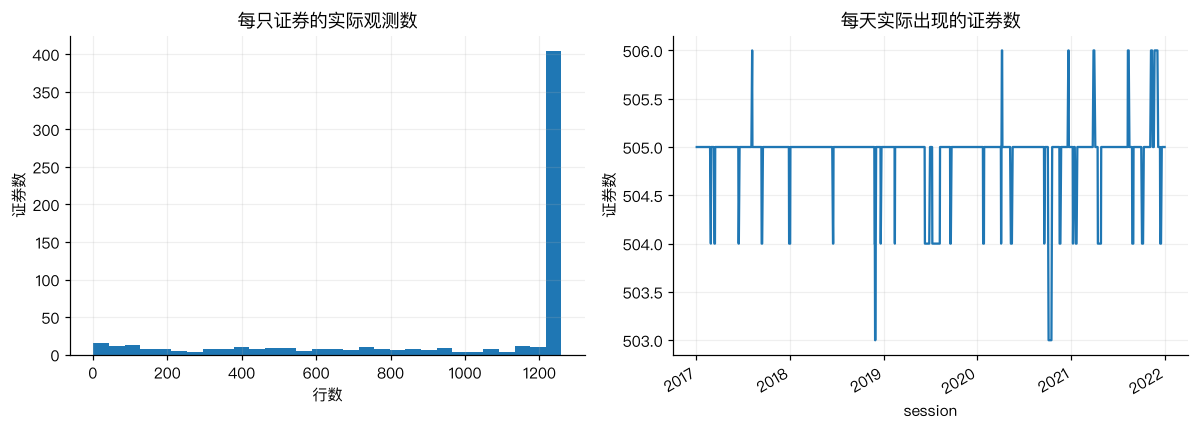

,symbol,first,last,rows
sec_id,,,,
42839,STJ,2017-01-03,2017-01-04,2
33968,BMS,2019-06-07,2019-06-10,2
6285863,ARNC,2020-04-06,2020-04-07,2
6996103,VSCO,2021-08-10,2021-08-13,4
7136104,KD,2021-11-08,2021-11-12,5
4448801,SEDG,2021-12-20,2021-12-31,9
2998449,EPAM,2021-12-20,2021-12-31,9
36596,FDS,2021-12-20,2021-12-31,9


In [4]:
coverage=panel.groupby("sec_id").agg(symbol=("symbol","last"),first=("session","min"),last=("session","max"),rows=("session","size"))
fig,axs=plt.subplots(1,2,figsize=(11,4))
coverage.rows.hist(bins=30,ax=axs[0]); axs[0].set_title("每只证券的实际观测数"); axs[0].set_xlabel("行数"); axs[0].set_ylabel("证券数")
counts=panel.groupby("session").sec_id.nunique(); counts.plot(ax=axs[1],title="每天实际出现的证券数")
axs[1].set_ylabel("证券数"); plt.tight_layout(); plt.show()
display(coverage.sort_values("rows").head(8))

**读图：** 不是每只证券都覆盖完整五年。减少可能来自上市、退市、成分变化或数据缺失。每天出现的数量不等于当日官方 S&P 500 成分数量；本文件不能单独证明动态指数成员身份。

## 2. 用交易日历定位一个具体标的

选择 AAPL 是为了展示检查，不代表只检查它就验收了整个面板。按 XNYS 日历比较首尾范围内的日期，并把缺日列出来；这个日历作为美国常规交易日参照，不解决所有证券特有停牌。

In [5]:
import exchange_calendars as xc
aapl=panel[panel.symbol=="AAPL"].sort_values("session")
assert aapl.sec_id.nunique()==1
cal=xc.get_calendar("XNYS",start=str(aapl.session.min().date()),end=str(aapl.session.max().date()))
expected=pd.DatetimeIndex(cal.sessions).tz_localize(None)
actual=pd.DatetimeIndex(aapl.session)
print("AAPL实际行数：",len(actual),"；参照交易日：",len(expected))
print("缺日：",expected.difference(actual).strftime("%Y-%m-%d").tolist())
print("额外日期：",actual.difference(expected).strftime("%Y-%m-%d").tolist())

AAPL实际行数： 1259 ；参照交易日： 1259
缺日： []
额外日期： []


## 3. 复权字段必须解释后再计算

目标仓库 loader 明确保留 `adj_factor`，没有在加载时直接改写 OHLC。文件还含其他 adjustment 字段。本书不猜乘除方向、不把拆股调整冒充含分红总收益。下面检查 AAPL 拆股附近字段，让下一步核对有具体对象。

In [6]:
cols=["session","close","adj_factor","vol_adj_factor","adjustment_factor","adjustment_reason"]
display(aapl[aapl.session.between("2020-08-27","2020-09-02")][cols])

,session,close,adj_factor,vol_adj_factor,adjustment_factor,adjustment_reason
4696,2020-08-27,500.04,8.100549,7.0,NaN,None
4697,2020-08-28,499.23,8.100549,7.0,NaN,None
4698,2020-08-31,129.04,32.402197,28.0,0.25,Subdiv
4699,2020-09-01,134.18,32.402197,28.0,NaN,None
4700,2020-09-02,131.40,32.402197,28.0,NaN,None


## 4. 本次验收到哪

已取得固定来源原件、SHA-256、字段与覆盖诊断。没有把整个面板认证为全市场完整，也没有建立原始报价、公司行动和历史证券身份的完整链。因此本书输出质量研究，不发布全市场策略收益。

数据归属：© AlgoSeek LLC，目标仓库获得面向该书读者的分发许可。数据不随代码 MIT 许可自动获得同等权利。[数据说明](https://github.com/stefan-jansen/machine-learning-for-trading/blob/main/data/README.md)、[AlgoSeek](https://algoseek.com)。